In [30]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os
path = r'.\Data\creditcard.csv'

# Exploratory Data Analysist

## Overview
Tập dữ liệu này bao gồm các giao dịch bằng thẻ tín dụng được thực hiện vào tháng 9 năm 2013 bởi các chủ thẻ tại châu Âu.
Tập dữ liệu ghi lại các giao dịch diễn ra trong hai ngày, trong đó có 492 giao dịch gian lận trên tổng số 284.807 giao dịch.

Dữ liệu này chỉ bao gồm các biến đầu vào dạng số đã được biến đổi thông qua PCA. Vì lý do bảo mật nên thông tin của các đặc trưng gốc không được cung cấp. Các đặc trưng từ V1, V2, … đến V28 là những thành phần chính thu được từ PCA; các đặc trưng duy nhất không trải qua biến đổi PCA là `Time`  và `Amount`.

Trong đó:
- `Time`: ghi lại số giây trôi qua giữa mỗi giao dịch và giao dịch đầu tiên trong tập dữ liệu (0: Giao dịch đầu tiên, 10: Giao dịch xảy ra 10 giây sau giao dịch đầu tiên, 100:  Giao dịch xảy ra 100 giây sau giao dịch đầu tiên)
- `Amount`: là số tiền của giao dịch.
  
Feature `Class` là biến mục tiêu nhị phân với `1` phản ánh giao dịch gian lận và `0` trong các trường hợp còn lại.

In [2]:
df = pd.read_csv(path)

In [3]:
df.shape

(284807, 31)

In [4]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
df.sample(5) 

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
1138,884.0,-0.386254,1.011132,1.284208,0.086669,0.029333,-1.049492,0.606984,-0.023828,-0.274317,...,-0.267944,-0.755014,0.002926,0.313527,-0.184065,0.074469,0.238919,0.097903,1.29,0
31805,36523.0,-0.242395,0.103822,0.849044,0.248043,2.279498,4.282830,-0.394871,0.665881,0.562791,...,-0.121028,0.049521,-0.035182,1.000817,-0.187560,-0.375698,-0.448293,-0.388955,1.00,0
167765,118873.0,2.189746,-1.720089,-0.172936,-1.552070,-1.696588,0.127794,-1.785045,0.066990,-0.620192,...,-0.142578,0.056629,0.307461,0.456363,-0.486543,-0.268160,0.057383,-0.018148,52.00,0
51274,44869.0,-0.151873,1.509172,-0.081691,0.968039,0.146563,-1.168212,0.729946,0.093938,-0.868671,...,0.188319,0.693559,0.050919,0.432391,-0.649260,-0.416893,0.322601,0.170899,1.79,0
243983,152157.0,1.940737,-0.550331,-0.526283,0.377905,-0.487533,-0.164176,-0.530768,-0.096509,1.143178,...,0.214957,0.802604,-0.015393,-0.552721,-0.119087,0.659043,-0.022035,-0.043565,59.90,0


In [6]:
df.info()  

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [7]:
df.dtypes

Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

### Đánh giá
- Tập dữ liệu chứa 284807 hàng và 31 cột
- Toàn bộ các feature đều có kiểu là `float` hoặc `int`
- `V1`-`V28` là các feature đã được xử lý PCA nên không thể phân tích ý nghĩa của các feature này

## Detect Missing Value, Duplicate Value

In [8]:
print("Missing Values:", df.isnull().sum().sum())
dup = df.duplicated(keep= False).sum()
print("Duplicate Values:", dup,f"({dup/len(df):.2%})")
amount_lt_0, amount_eq_0 = (df.Amount < 0).sum(), (df.Amount == 0).sum()
print("Amount < 0:", amount_lt_0)
print("Amount == 0:", amount_eq_0, f"({amount_eq_0/len(df):.2%})")

print("Distribution of transactions with amount == 0, by class")
print(df[df.Amount == 0].Class.value_counts())
print("Distribution of duplicate transactions, by class")
print(df[df.duplicated(keep=False)].Class.value_counts())




Missing Values: 0
Duplicate Values: 1854 (0.65%)
Amount < 0: 0
Amount == 0: 1825 (0.64%)
Distribution of transactions with amount == 0, by class
Class
0    1798
1      27
Name: count, dtype: int64
Distribution of duplicate transactions, by class
Class
0    1822
1      32
Name: count, dtype: int64


### Đánh giá
- Không có missing value
- Có 1854 dòng trùng lặp (0.64\%), trong đó có 32 giao dịch gian lận
- Có 1825 giao dịch với số tiền bằng 0 (65\%), trong đó có 27 giao dịch gian lận

In [9]:
print(df[df.duplicated(keep=False)].Class.value_counts())

Class
0    1822
1      32
Name: count, dtype: int64


## Satistic

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [11]:
df[["Time", "Amount"]].agg(["mean", "median", "std", "skew", "kurt"])



,Time,Amount
mean,94813.859575,88.349619
median,84692.000000,22.000000
std,47488.145955,250.120109
skew,-0.035568,16.977724
kurt,-1.293530,845.092646


In [12]:
print("Time from:", f"{min(df.Time):.0f}", "to:", f"{max(df.Time):.0f}")
print("Time (hours) from:", f"{min(df.Time)/24:.0f}", "to", f"{max(df.Time)/3600:.0f}")

df['Hour'] = (df['Time']//3600)%24

Time from: 0 to: 172792
Time (hours) from: 0 to 48


Text(0.5, 1.0, 'Distribution of Amount')

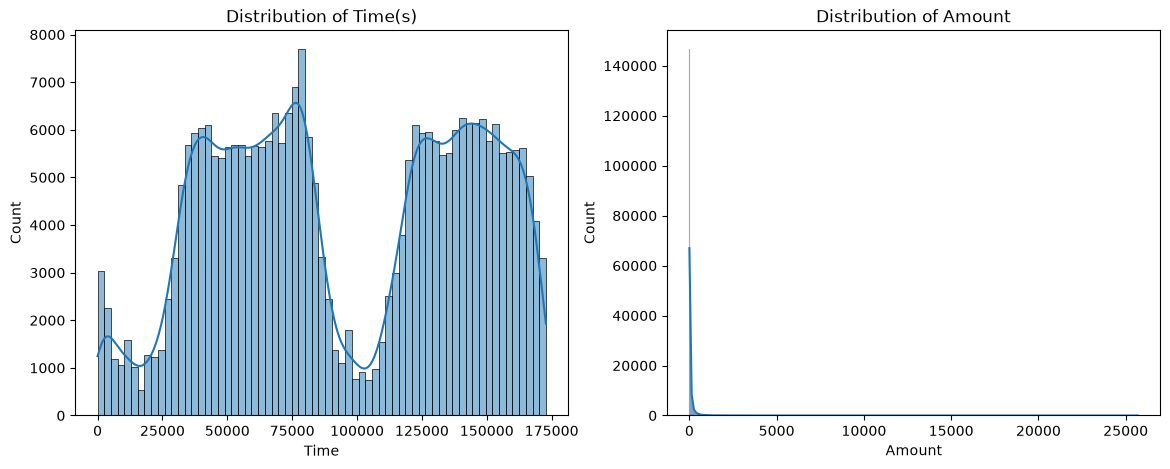

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14,5))
sns.histplot(data=df, x='Time', kde=True,ax=ax[0])
ax[0].set_title("Distribution of Time(s)")

sns.histplot(data=df, x='Amount', kde=True, ax=ax[1])
ax[1].set_title("Distribution of Amount")



### Đánh giá:
- Feature `Amount` có trung bình 88.35 nhưng có trung vị là 22.00 và `max` là 25691.16. Cho thấy Amount đang có phân phối lệch phải và xuất hiện outlier mạnh.
- `Time` trải từ 0 đến 172792, tương đương từ 0 đến 48h.

## Variable analysis

### Target variable: `Class`

Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827
1     0.173
Name: count, dtype: float64
Imbalance ratio: 0.17%


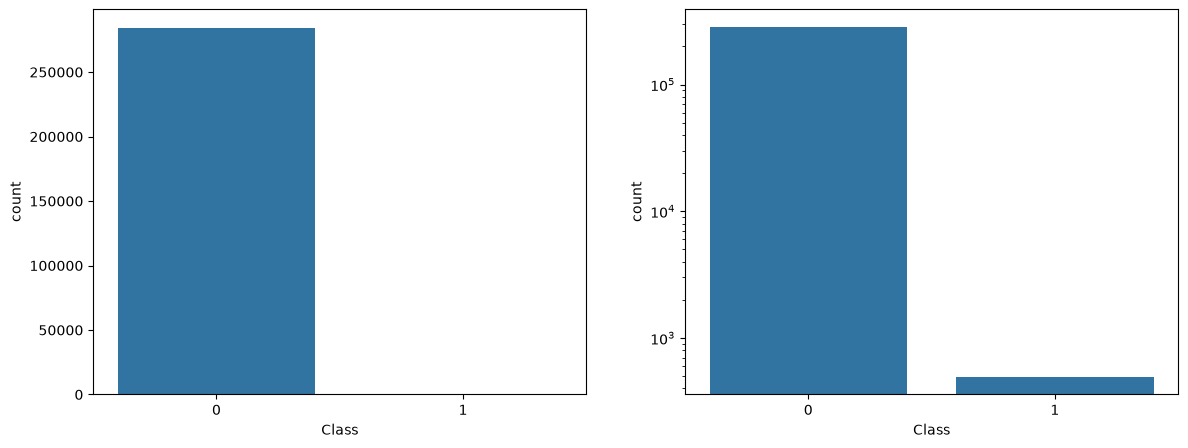

In [14]:
var_cl = df.Class.value_counts()
var_cl_ratio = (var_cl/len(df)*100).round(3)
print(var_cl)
print(var_cl_ratio)
print("Imbalance ratio:", f"{(var_cl[1]/var_cl[0]):.2%}")

fig, ax = plt.subplots(1,2,figsize=(14,5))
sns.countplot(data=df, x = 'Class', ax=ax[0])
sns.countplot(data=df, x = 'Class', ax=ax[1])
ax[1].set_yscale("log")


### Đánh giá:
- Các giao dich gian lận chỉ chiếm 0.17%, dẫn đến sự mất cân bằng dữ liệu trong dataset

### `Amount`

0.500      22.000
0.750      77.165
0.900     203.000
0.950     365.000
0.990    1017.970
0.999    3000.000
Name: Amount, dtype: float64


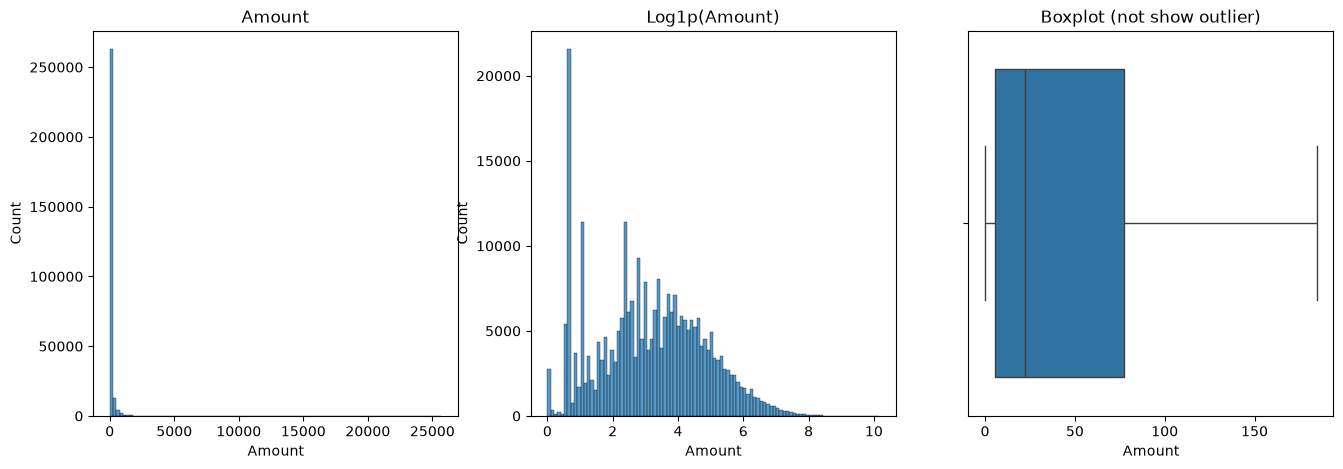

In [15]:
fig, ax = plt.subplots(1,3,figsize=(16, 5))
sns.histplot(df['Amount'], bins = 100, ax=ax[0])
sns.histplot(np.log1p(df["Amount"]), bins=100, ax=ax[1])
sns.boxplot(x=df.Amount, ax=ax[2], showfliers=False)
ax[0].set_title("Amount")
ax[1].set_title("Log1p(Amount)")
ax[2].set_title("Boxplot (not show outlier)")
print(df.Amount.quantile([.5, .75, .9, .95, .99, .999]))
plt.show()

### Đánh giá
- Dựa vào biểu đồ histogram cho thấy các giao dịch phần lớn là giao dịch nhỏ lẻ, sự xuất hiện của các giao dịch với số tiền lớn đã làm cho đồ thị bị lệch phải nặng
- Dựa vào biểu đồ Boxplot và khoảng tứ phân vị cho thấy 50 \% có giá trị giao dịch <= 22.00, 75\% có giá trị  giao dịch <= 77.71 và 95\% giao dịch có giá trị giao dịch <= 365
- Phép biến đổi log1p đưa phân phối về gần phân phối chuẩn
  

### `Time`

Text(0.5, 1.0, 'Transaction by time')

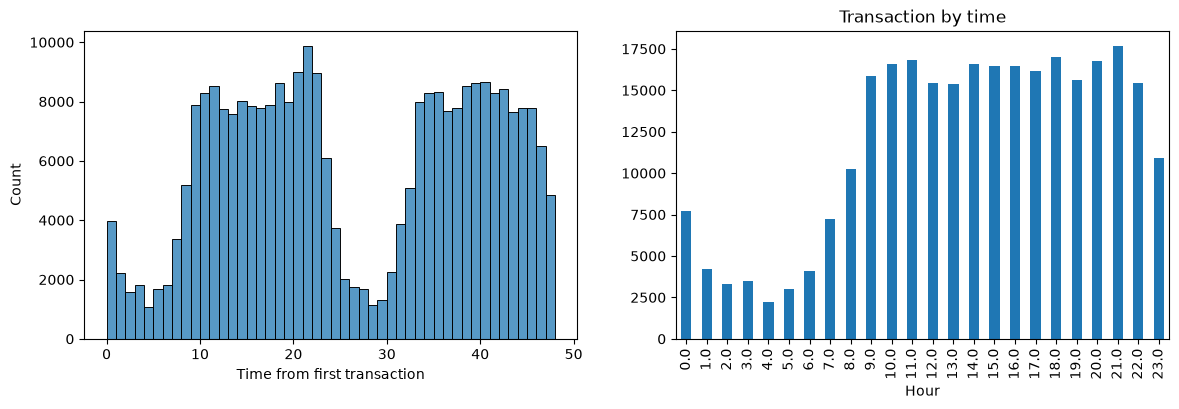

In [16]:
fig, ax = plt.subplots(1, 2,figsize=(14,4))
sns.histplot(df.Time / 3600, bins = 48, ax=ax[0])
ax[0].set_xlabel("Time from first transaction")
df.groupby("Hour").size().plot(kind='bar', ax=ax[1])
ax[1].set_title("Transaction by time")

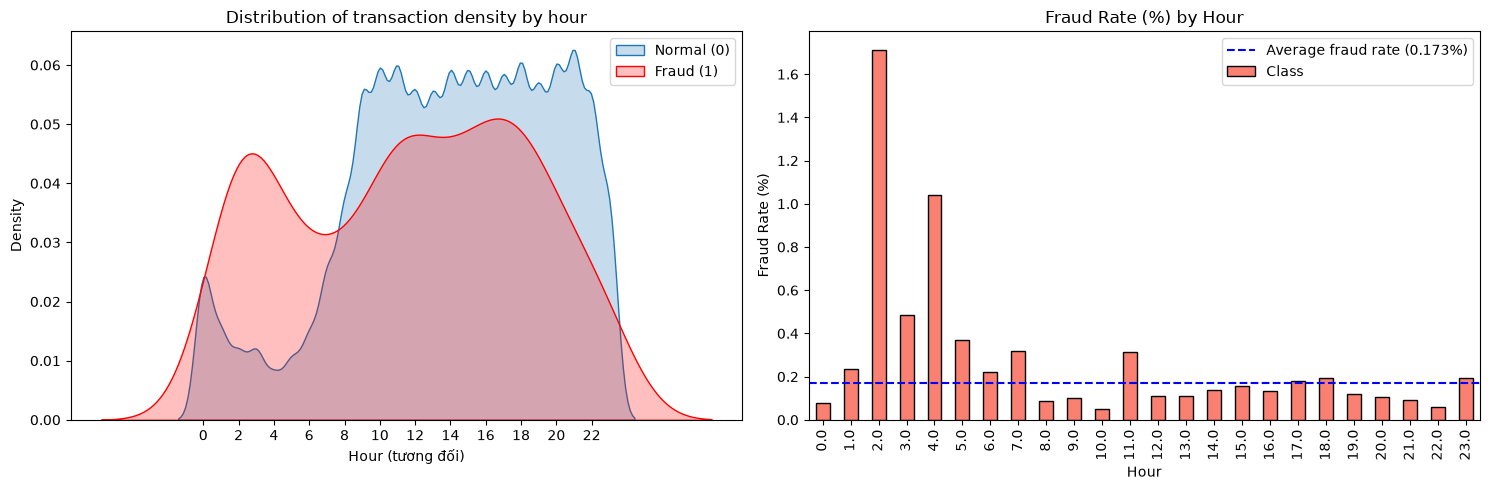

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

sns.kdeplot(data=df[df['Class'] == 0], x='Hour', label='Normal (0)', fill=True, ax=ax[0])
sns.kdeplot(data=df[df['Class'] == 1], x='Hour', label='Fraud (1)', color='red', fill=True, ax=ax[0])
ax[0].set_title("Distribution of transaction density by hour")
ax[0].set_xlabel("Hour (tương đối)")
ax[0].set_xticks(range(0, 24, 2))
ax[0].legend()


fraud_rate_by_hour = df.groupby('Hour')['Class'].mean() * 100
fraud_rate_by_hour.plot(kind='bar', color='salmon', edgecolor='black', ax=ax[1])
ax[1].axhline(df['Class'].mean() * 100, color='blue', linestyle='--', label='Average fraud rate (0.173%)')
ax[1].set_title("Fraud Rate (%) by Hour")
ax[1].set_xlabel("Hour")
ax[1].set_ylabel("Fraud Rate (%)")
ax[1].legend()

plt.tight_layout()
plt.show()

### Đánh giá
- Dựa vào biểu đồ `Distribution of transaction density by hour` các giao dịch gian lận có mật độ tập trung cao trong khoảng khung giờ từ 2-5h so với giao dịch đầu tiên (+24h)
- Điều này cho thấy các giao dịch gian lận thường xu hướng xảy ra vào 1 khung giờ cụ thể (Ví dụ như vào nửa đêm hoặc rạng sáng).
- Biểu đồ `Fraud Rate (%) by Hour` cũng cho thấy kết quả tương tự, khi tỷ lệ các giao dịch gian lận vào khung giờ từ 2h-5h cao hơn đáng kể so với các khung giờ khác.

Statistics for Amount by Class:


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


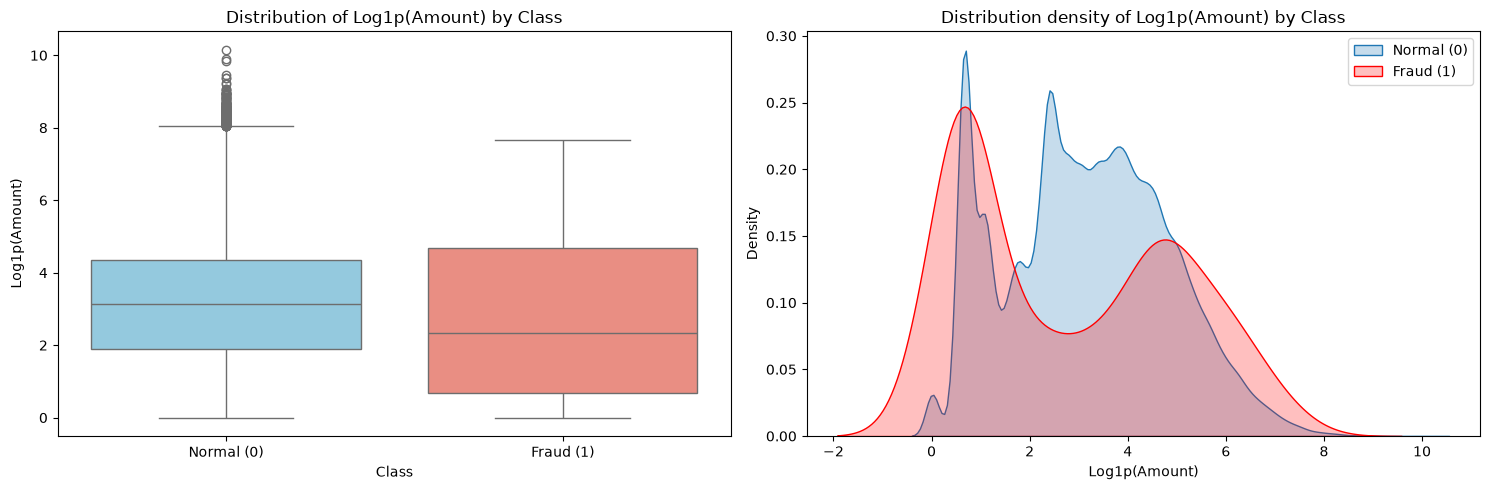

In [ ]:

print("Statistics for Amount by Class:")
display(df.groupby('Class')['Amount'].describe())
fig, ax = plt.subplots(1, 2, figsize=(15, 5))


sns.boxplot(
    data=df, 
    x='Class', 
    y=np.log1p(df['Amount']), 
    hue='Class', 
    palette=['skyblue', 'salmon'], 
    legend=False, 
    ax=ax[0]
)
ax[0].set_title("Distribution of Log1p(Amount) by Class")
ax[0].set_xticks([0, 1])
ax[0].set_xticklabels(['Normal (0)', 'Fraud (1)'])
ax[0].set_ylabel("Log1p(Amount)")

sns.kdeplot(x=np.log1p(df[df['Class'] == 0]['Amount']), label='Normal (0)', fill=True, ax=ax[1])
sns.kdeplot(x=np.log1p(df[df['Class'] == 1]['Amount']), label='Fraud (1)', color='red', fill=True, ax=ax[1])
ax[1].set_title("Distribution density of Log1p(Amount) by Class")
ax[1].set_xlabel("Log1p(Amount)")
ax[1].legend()

plt.tight_layout()
plt.show()

### Đánh giá
- Trung vị của nhóm giao dịch gian lận thấp hơn nhưng trung bình lại cao hơn so với những giao dịch hợp lệ.
- Trong khi giao dịch hợp lệ (`Normal (0)`, màu xanh) tập trung chủ yếu ở vùng giá trị trung bình từ 2 đến 5 (tương đương khoảng 6 – 150), thì đường mật độ gian lận màu đỏ tách thành 2 đỉnh sóng rõ rệt.

### `V1 - V28`

Top 10 biến PCA có độ nhọn (Kurtosis) / outlier mạnh nhất:


,Min,Median,Max,Std,Skewness,Kurtosis
V28,-15.43,0.01,33.85,0.33,11.19,933.40
V23,-44.81,-0.01,22.53,0.62,-5.88,440.09
V7,-43.56,0.04,120.59,1.24,2.55,405.61
V20,-54.50,-0.06,39.42,0.77,-2.04,271.02
V27,-22.57,0.00,31.61,0.40,-1.17,244.99
V8,-73.22,0.02,20.01,1.19,-8.52,220.59
V21,-34.83,-0.03,27.20,0.73,3.59,207.29
V5,-113.74,-0.05,34.80,1.38,-2.43,206.90
V2,-72.72,0.07,22.06,1.65,-4.62,95.77
V17,-25.16,-0.07,9.25,0.85,-3.84,94.80


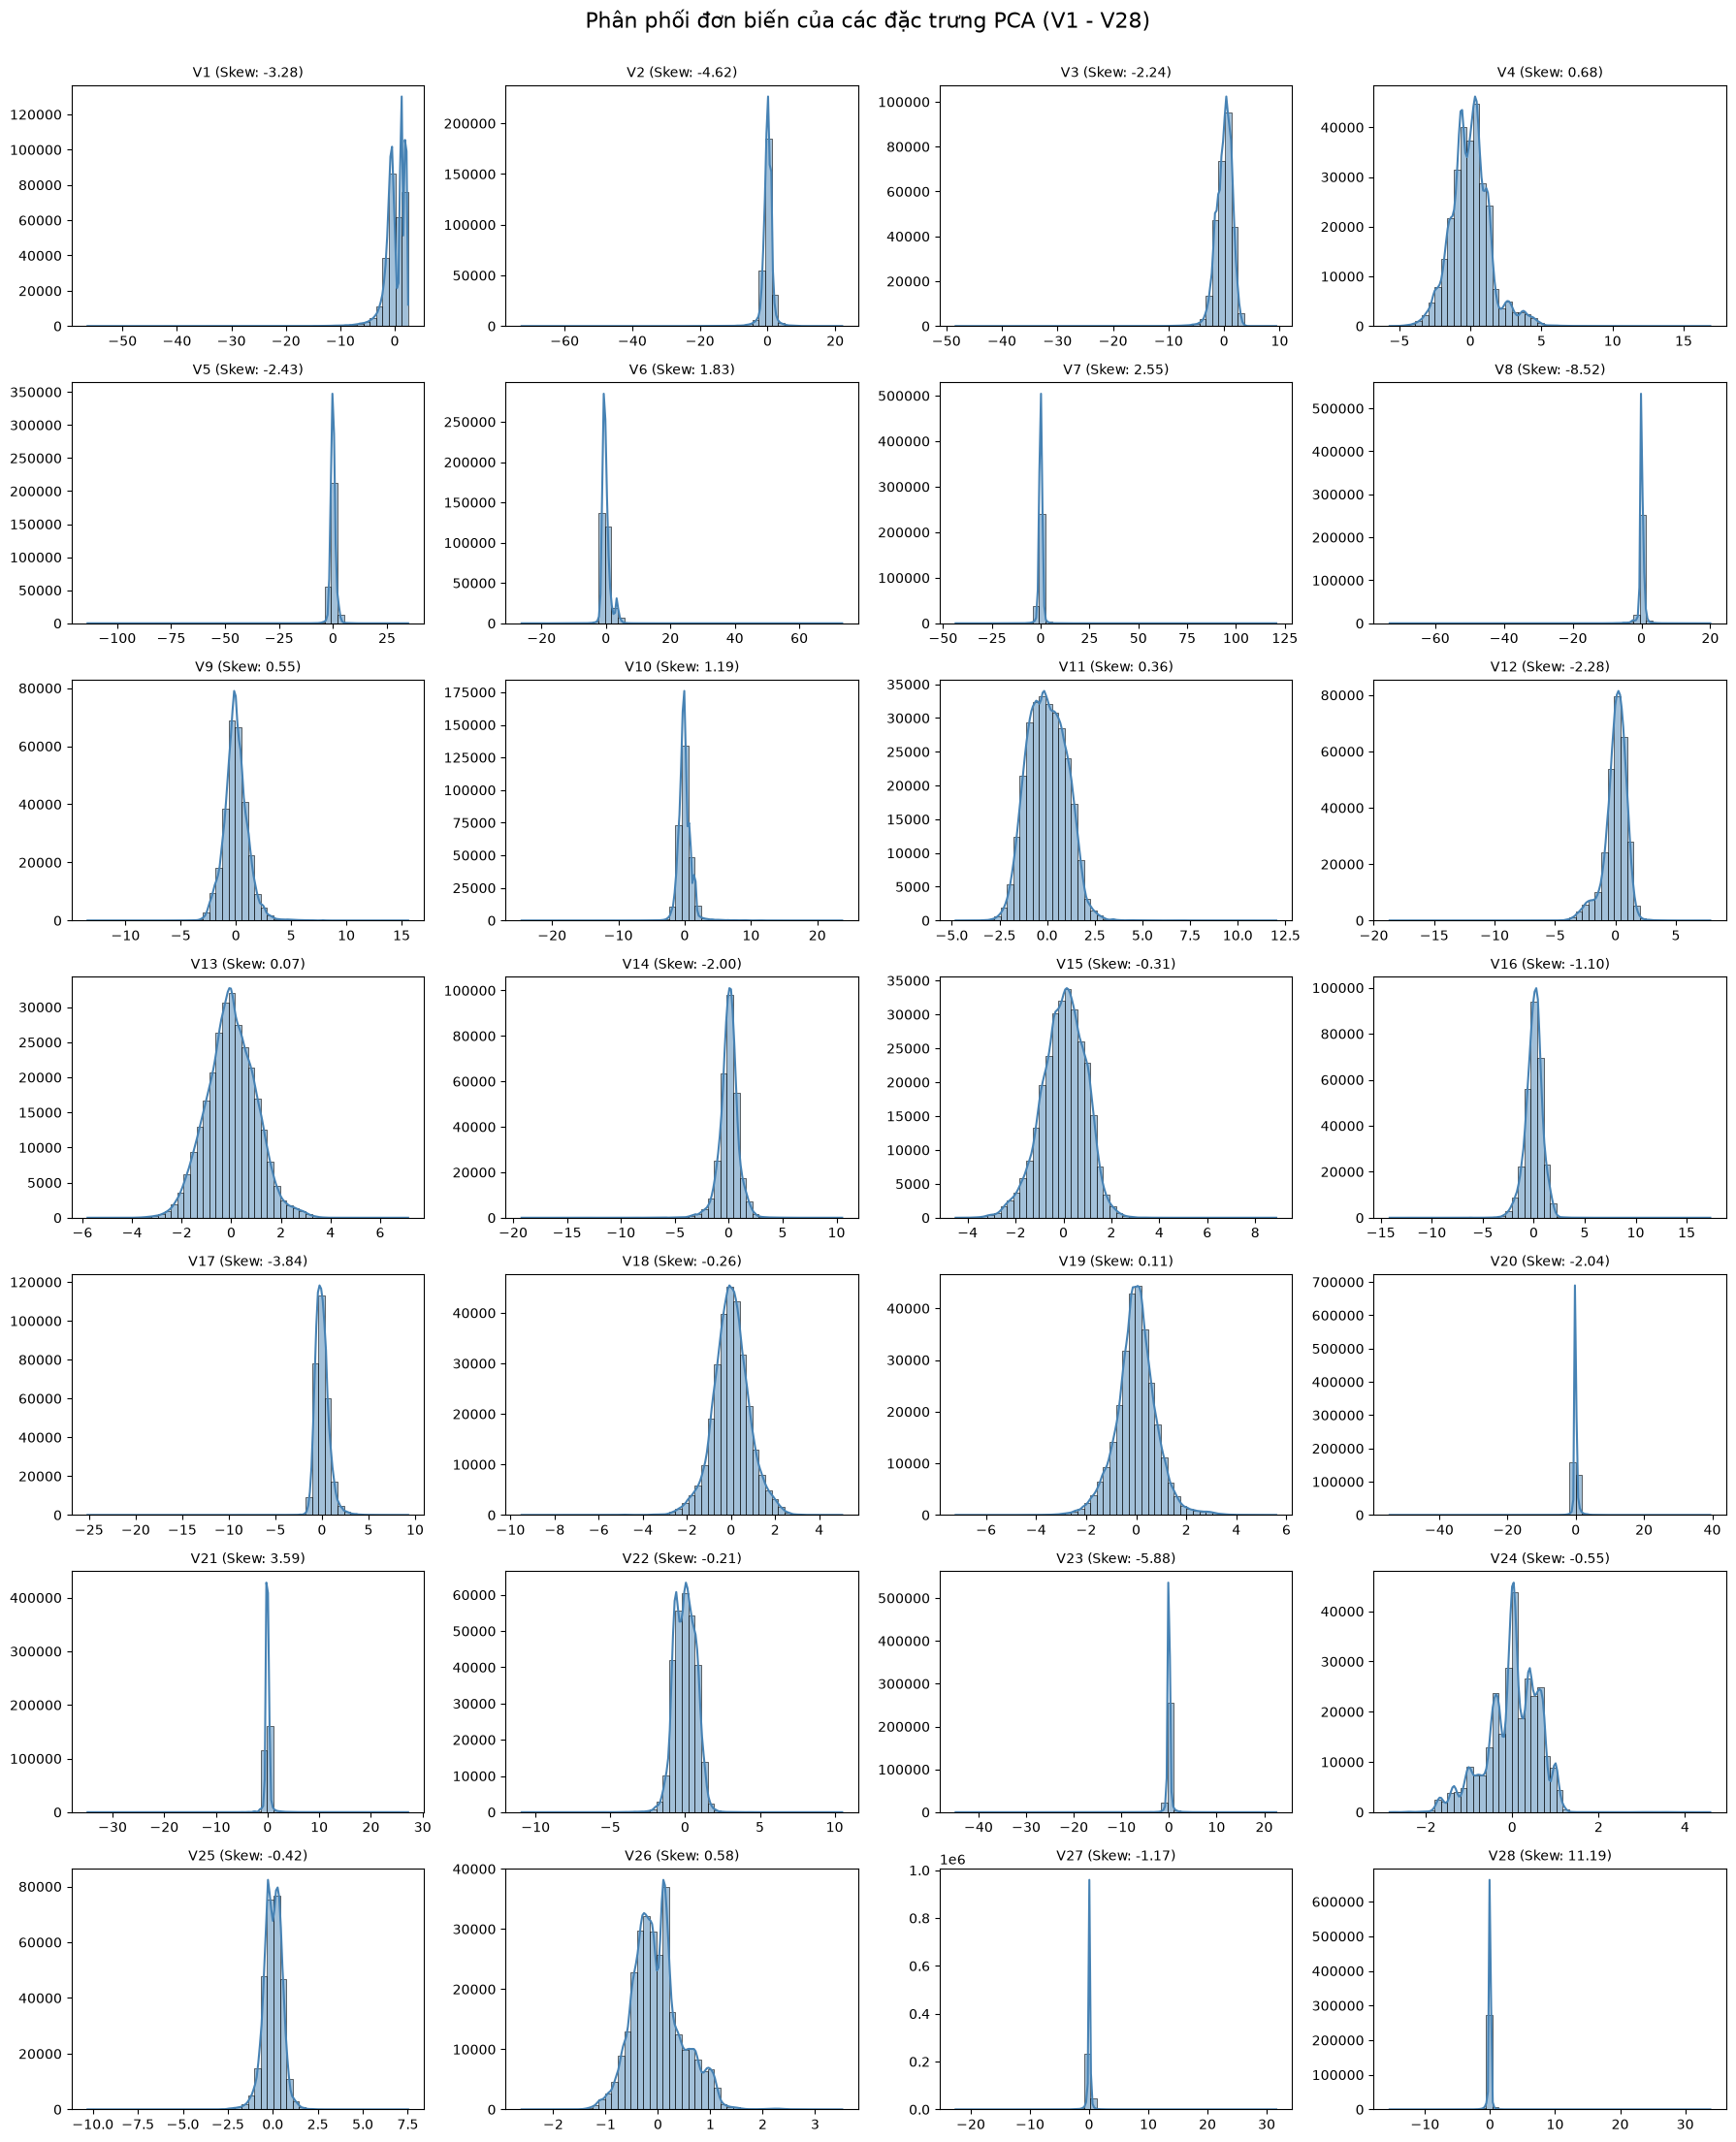

In [27]:
v_cols = [f'V{i}' for i in range(1, 29)]

# 1. Bảng thống kê độ lệch (Skewness) và độ nhọn (Kurtosis) của V1-V28
v_stats = pd.DataFrame({
    'Min': df[v_cols].min(),
    'Median': df[v_cols].median(),
    'Max': df[v_cols].max(),
    'Std': df[v_cols].std(),
    'Skewness': df[v_cols].skew(),
    'Kurtosis': df[v_cols].kurt()
}).sort_values(by='Kurtosis', ascending=False)

print("Top 10 biến PCA có độ nhọn (Kurtosis) / outlier mạnh nhất:")
display(v_stats.head(10).round(2))

# 2. Vẽ lưới biểu đồ phân phối (Grid 7x4) cho toàn bộ 28 biến
fig, axes = plt.subplots(7, 4, figsize=(18, 22))
axes = axes.flatten()

for i, col in enumerate(v_cols):
    sns.histplot(df[col], bins=50, kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f"{col} (Skew: {df[col].skew():.2f})", fontsize=10)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")

plt.suptitle("Phân phối đơn biến của các đặc trưng PCA (V1 - V28)", fontsize=16, y=1.002)
plt.tight_layout()
plt.show()

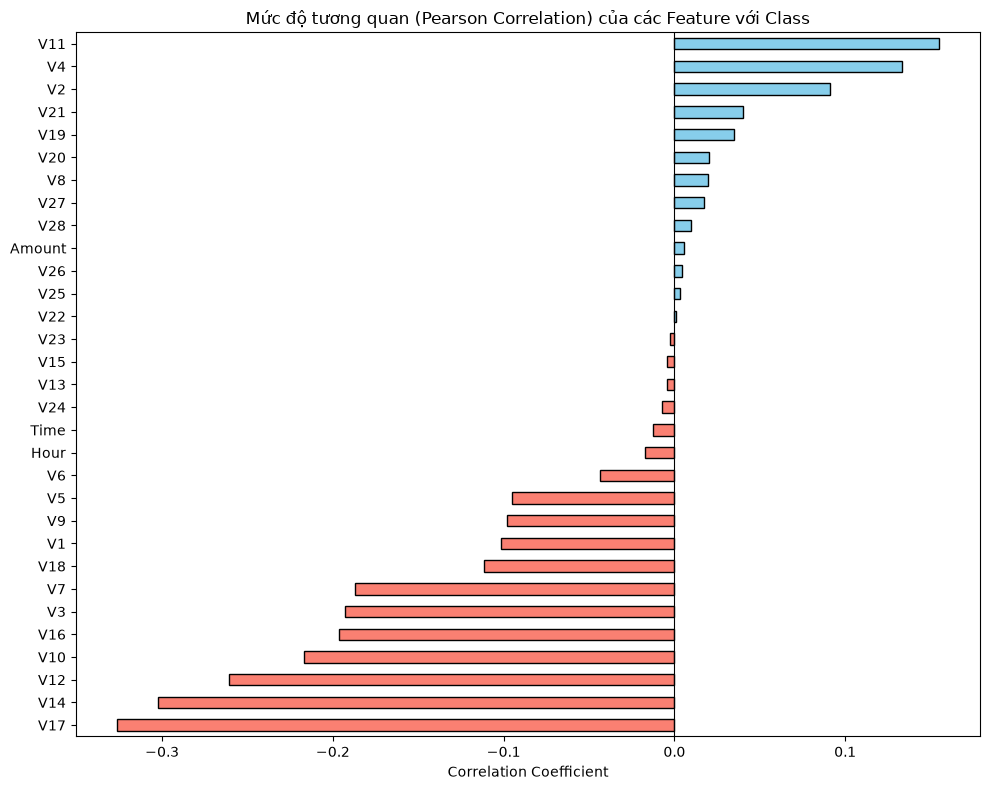

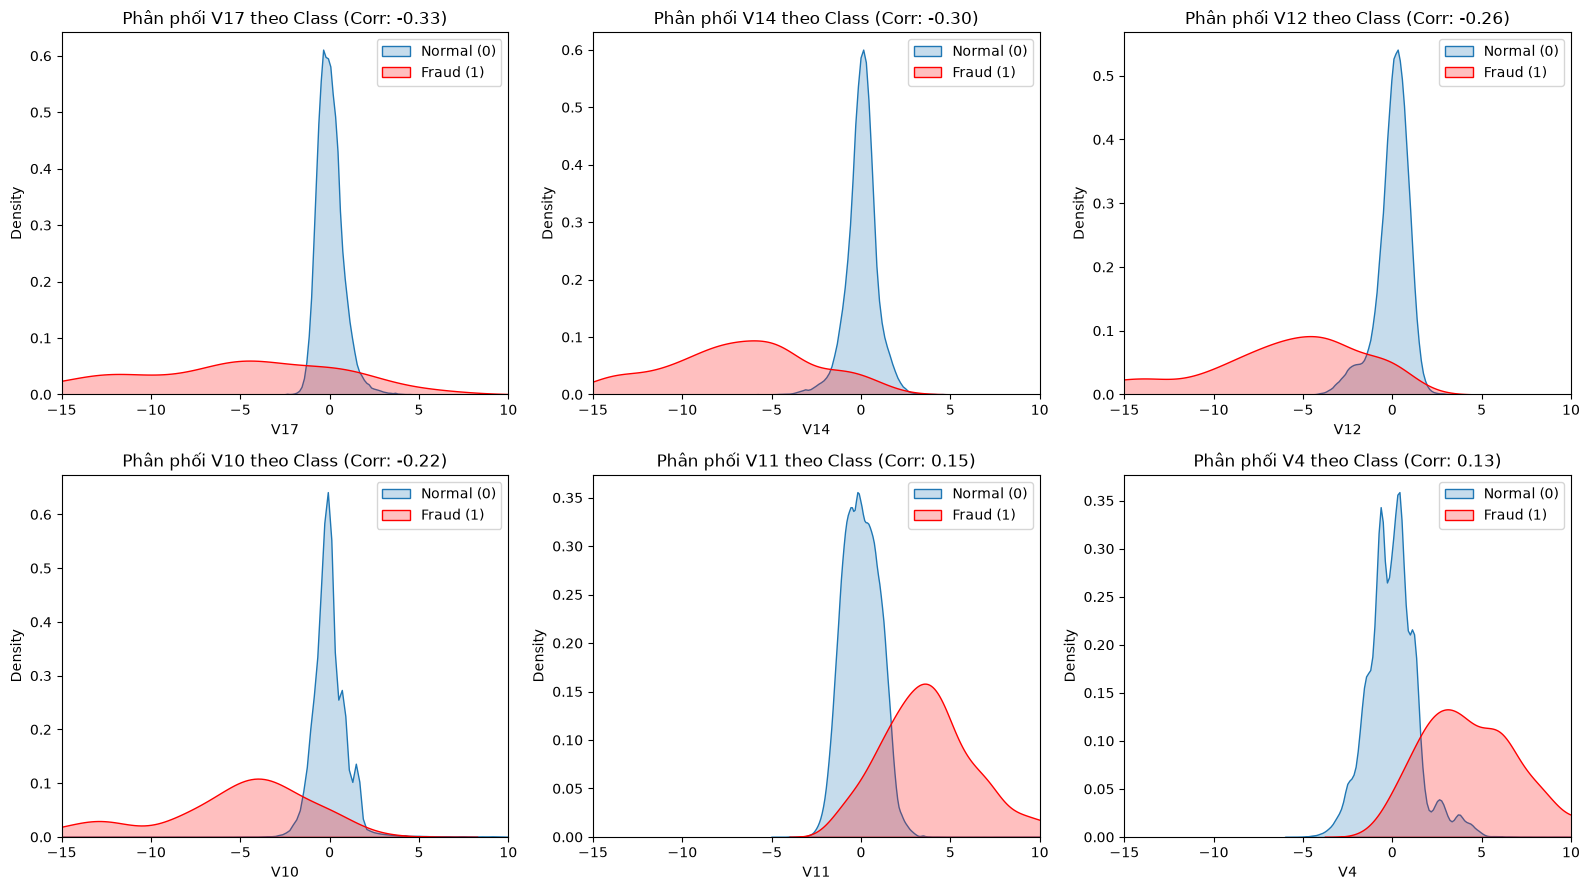

In [28]:
# 1. Tính độ tương quan của tất cả các biến với Class
corr_class = df.corr()['Class'].drop('Class').sort_values()

# Vẽ biểu đồ thanh ngang thể hiện mức độ tương quan với Class
plt.figure(figsize=(10, 8))
colors = ['salmon' if x < 0 else 'skyblue' for x in corr_class]
corr_class.plot(kind='barh', color=colors, edgecolor='black')
plt.title("Mức độ tương quan (Pearson Correlation) của các Feature với Class")
plt.xlabel("Correlation Coefficient")
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

# 2. Vẽ KDE Plot so sánh phân phối 2 lớp của Top 6 biến tương quan mạnh nhất
top_features = ['V17', 'V14', 'V12', 'V10', 'V11', 'V4']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(top_features):
    sns.kdeplot(x=df[df['Class'] == 0][col], label='Normal (0)', fill=True, ax=axes[i])
    sns.kdeplot(x=df[df['Class'] == 1][col], label='Fraud (1)', color='red', fill=True, ax=axes[i])
    axes[i].set_title(f"Phân phối {col} theo Class (Corr: {corr_class[col]:.2f})")
    axes[i].set_xlim(-15, 10) # Giới hạn trục X để nhìn rõ vùng tách biệt
    axes[i].legend()

plt.tight_layout()
plt.show()